# Energy Consumption Prediction using  
# Linear Regression

## Load Dataset

In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [203]:
import kagglehub
path = kagglehub.dataset_download("govindaramsriram/energy-consumption-dataset-linear-regression")

Using Colab cache for faster access to the 'energy-consumption-dataset-linear-regression' dataset.


In [204]:
df_train=pd.read_csv(path + '/train_energy_data.csv')
df_test=pd.read_csv(path + '/test_energy_data.csv')
df_train.head()

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,7063,76,10,29.84,Weekday,2713.95
1,Commercial,44372,66,45,16.72,Weekday,5744.99
2,Industrial,19255,37,17,14.30,Weekend,4101.24
3,Residential,13265,14,41,32.82,Weekday,3009.14
4,Commercial,13375,26,18,11.92,Weekday,3279.17


## Understanding Data

In [205]:
df_train.shape

(1000, 7)

In [206]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1000 non-null   object 
 1   Square Footage       1000 non-null   int64  
 2   Number of Occupants  1000 non-null   int64  
 3   Appliances Used      1000 non-null   int64  
 4   Average Temperature  1000 non-null   float64
 5   Day of Week          1000 non-null   object 
 6   Energy Consumption   1000 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 54.8+ KB


In [207]:
print(df_train.isnull().sum())
print()
print(df_test.isnull().sum())

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64


In [208]:
df_train.duplicated().sum()

np.int64(0)

## Outlier Detection

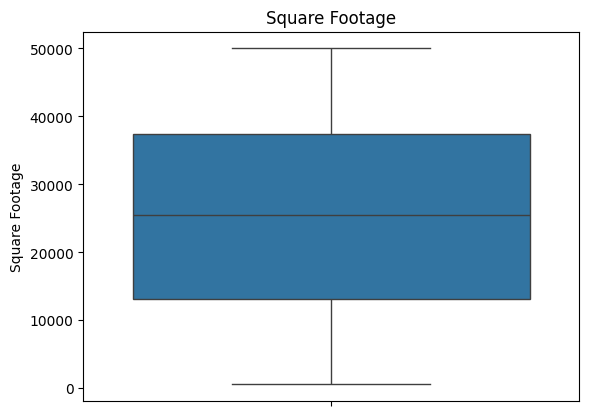

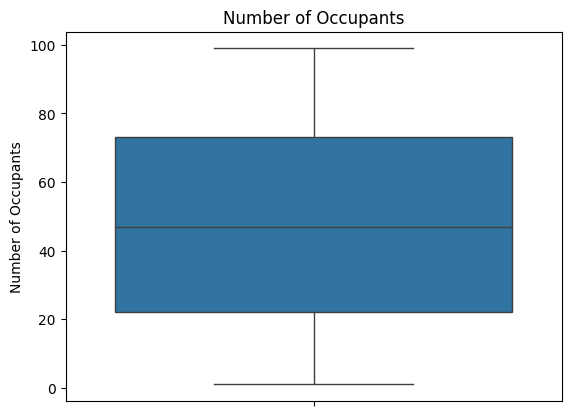

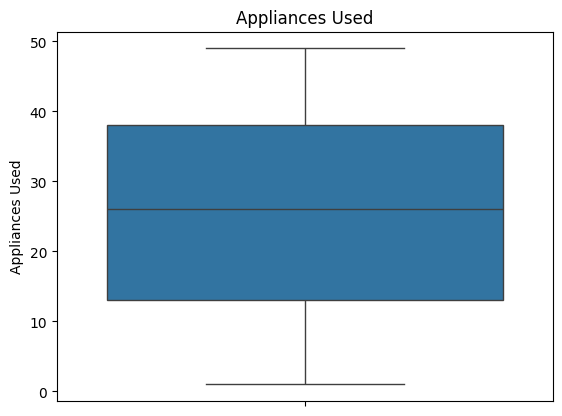

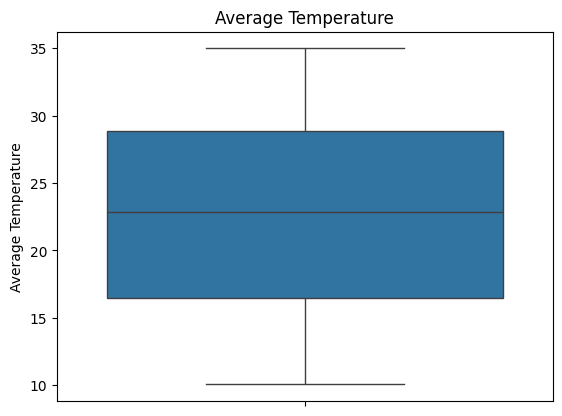

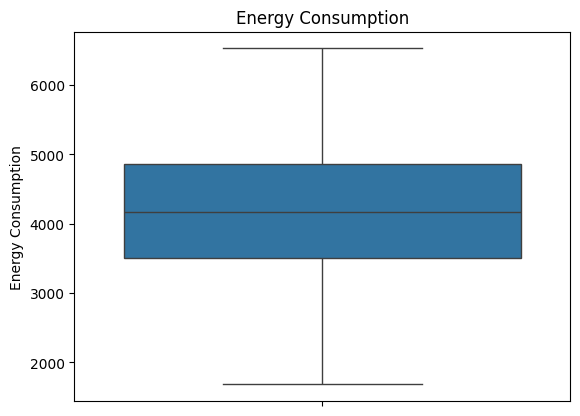

In [209]:
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
for cols in num_cols:
  sns.boxplot(df_train[cols])
  plt.title(str(cols))
  plt.show()

No outliers

## Encoding Categorical Columns

In [210]:
# We have two object cols Building Type,Day of Week
# We will encode both using OneHotEncoding
df_train['Building Type'].unique(),df_train['Day of Week'].unique()

(array(['Residential', 'Commercial', 'Industrial'], dtype=object),
 array(['Weekday', 'Weekend'], dtype=object))

In [211]:
encoded = pd.get_dummies(df_train[['Building Type', 'Day of Week']], dtype='int64')
df_train = pd.concat([df_train, encoded], axis=1).drop(columns=['Building Type', 'Day of Week'])

encoded_test=pd.get_dummies(df_test[['Building Type', 'Day of Week']], dtype='int64')
df_test = pd.concat([df_test, encoded_test], axis=1).drop(columns=['Building Type', 'Day of Week'])

df_train

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
0,7063,76,10,29.84,2713.95,0,0,1,1,0
1,44372,66,45,16.72,5744.99,1,0,0,1,0
2,19255,37,17,14.30,4101.24,0,1,0,0,1
3,13265,14,41,32.82,3009.14,0,0,1,1,0
4,13375,26,18,11.92,3279.17,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...
995,14419,68,44,23.95,3661.21,0,0,1,0,1
996,12194,7,22,14.67,3546.34,0,1,0,0,1
997,39562,88,20,32.18,5147.21,1,0,0,1,0
998,8348,67,37,16.48,3244.98,0,0,1,0,1


## EDA

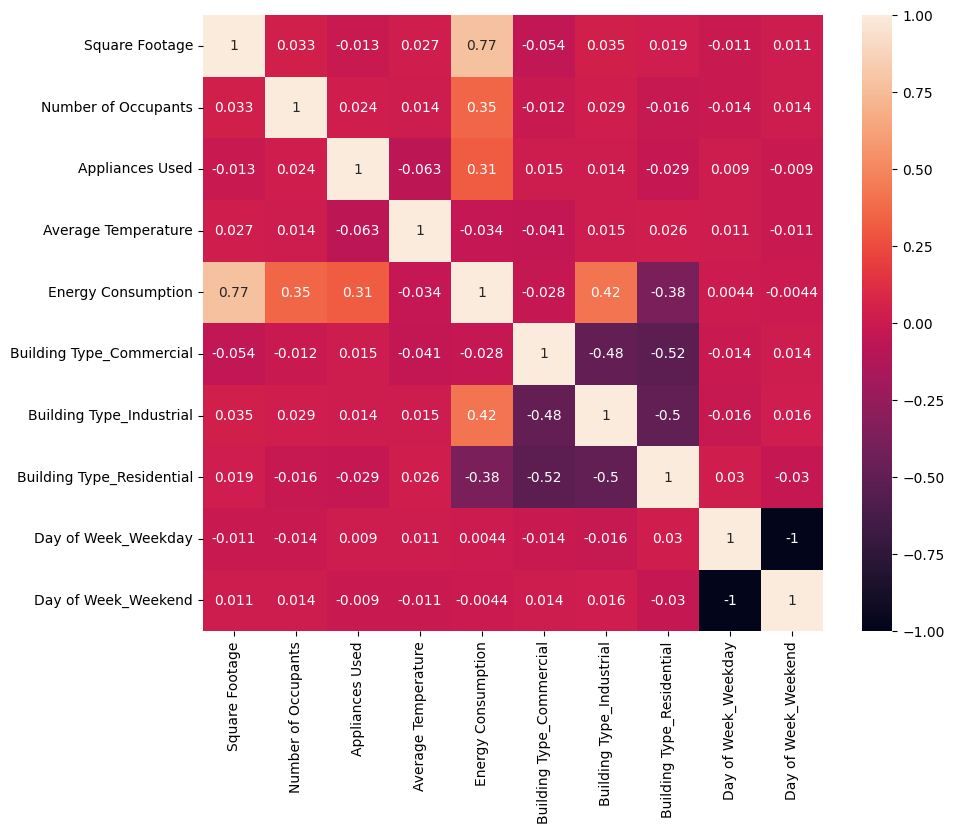

In [212]:
plt.figure(figsize=(10,8))
sns.heatmap(df_train.corr(),annot=True)
plt.show()

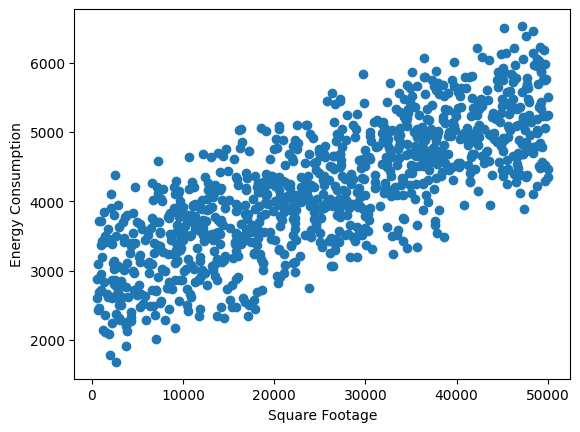

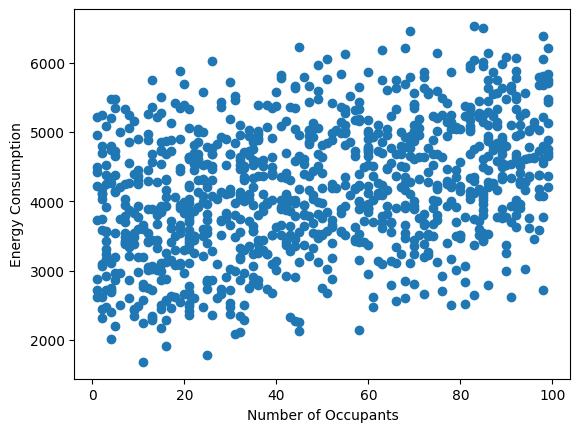

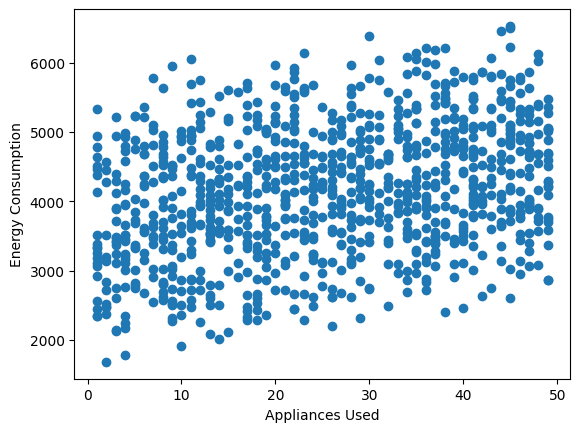

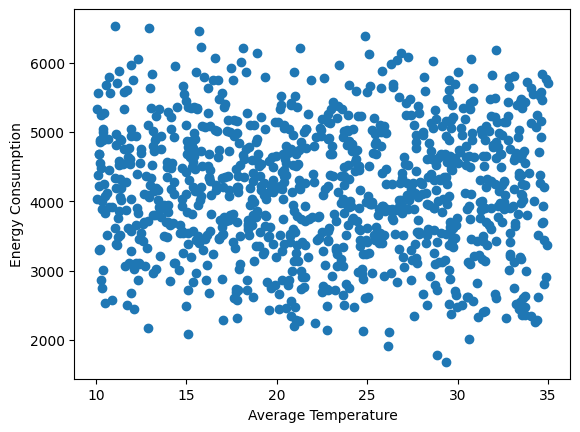

In [213]:
# Target column=Energy Consumption
# lets check its scatter plot with ecery other num col
num_cols.remove("Energy Consumption")

for col in num_cols:
  plt.scatter(df_train[col],df_train['Energy Consumption'])
  plt.xlabel(str(col))
  plt.ylabel("Energy Consumption")
  plt.show()

By the heatmap and scatter plot we confirm that feature Square Footage is highly correlated with the feature

## Feature Scaling and split

In [214]:
X=df_train.drop(columns='Energy Consumption').values
y=df_train['Energy Consumption'].values

X_train=df_train.drop(columns='Energy Consumption').values
y_train=df_train['Energy Consumption'].values

X_test=df_test.drop(columns='Energy Consumption').values
y_test=df_test['Energy Consumption'].values

In [215]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

## Model Training

In [216]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

## Model Evaluation

In [217]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,root_mean_squared_error

y_pred = model.predict(X_test)
print("MSE :",mean_squared_error(y_test,y_pred))
print("MAE :",mean_absolute_error(y_test,y_pred))
print("RMSE :",root_mean_squared_error(y_test,y_pred))
print("R2 Score :",r2_score(y_test,y_pred))

MSE : 0.00020154241157231491
MAE : 0.012161901170329656
RMSE : 0.014196563371897964
R2 Score : 0.9999999997063025


Verdict : model has R2_score of 0.99 meaning the model performs best on the testing data as well.  
Model Evaluation Status : Excellent model

## Graphical evalutaion

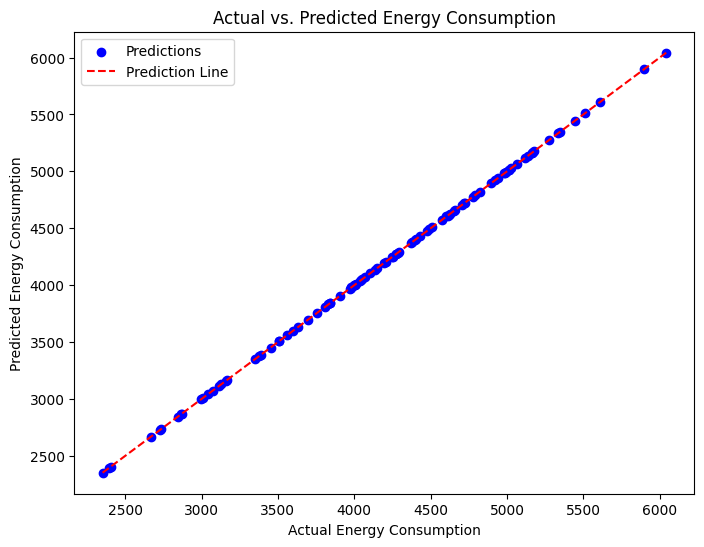

In [218]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred,color='blue', label='Predictions')
min_val = np.minimum(y_test.min(), y_pred.min())
max_val = np.maximum(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Prediction Line')
plt.xlabel('Actual Energy Consumption')
plt.ylabel('Predicted Energy Consumption')
plt.title('Actual vs. Predicted Energy Consumption')
plt.legend()
plt.show()